In [1]:
# imports to enable the notebook to access the src folder
import sys
import os
sys.path.append(os.path.dirname(os.getcwd()))

# import the necessary packages
from src.molecules import StructuralValidator
from src.pure import PropertyCalculator
from src.pure import AntoineCalculator
from src.data import load_unifac_data
from src.mixture.unifac.pyomo_vle import pyo_vle
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# step1: define the compounds
mixture = {'water': {'H2O':1},
           "E": {'CH3':2, 'CH2':2, 'CH':1, 'HCOO':1}}
# validate the structures
validator = StructuralValidator()
validator.validate(mixture)

{'water': True, 'E': True}

In [ ]:
# step2: calculate the required properties
prop_list = ['tc', 'pc', 'tb', 'ac', 'hv']
pure_calc = PropertyCalculator()
pure_props = pure_calc.calculate(mixture, prop_list)
# fix the properties of acetone
#pure_props['acetone']['tc'] = 508.1
# pure_props['acetone']['pc'] = 48.0
# pure_props['acetone']['tb'] = 329.3
pure_props

{'water': {'tc': 646.9999999999999,
  'pc': 220.6400000000002,
  'tb': 373.1499999999999,
  'ac': 0.3448609999999985,
  'hv': 43.9883},
 'E': {'tc': 589.9854577230362,
  'pc': 33.559848008495194,
  'tb': 408.2734535772965,
  'ac': 0.4121268040277704,
  'hv': 27.132}}

In [4]:
# step3: calculate the Antoine coefficients: using acentric factor method
antoine_params_ac = {}
antoine_calc = AntoineCalculator()
for compound, props in pure_props.items():
    results = antoine_calc.calculate_antoine_parameters(mixture, critical_properties=props,method='acentric_factor')
    print('optimization results was', results['termination_condition'] )
    antoine_params_ac[compound] = {}
    antoine_params_ac[compound]['A'] = results['A']
    antoine_params_ac[compound]['B'] = results['B']
    antoine_params_ac[compound]['C'] = results['C']
antoine_params_ac

Characteristic points (T [K], P [bar]): (373.1499999999999, 1.01325), (452.89999999999986, 9.972940978725989), (646.9999999999999, 220.6400000000002)
optimization results was optimal
Characteristic points (T [K], P [bar]): (408.2734535772965, 1.01325), (412.9898204061253, 1.2992513633847769), (589.9854577230362, 33.559848008495194)
optimization results was optimal


{'water': {'A': 5.276150790167597,
  'B': 1810.313164589222,
  'C': -29.66536409838349},
 'E': {'A': 2.3389137287696284,
  'B': 226.7788486407892,
  'C': -311.0768442333829}}

In [5]:
# step3: calculate the Antoine coefficients: using enthalpy of vaporization method
antoine_params_hv = {}
for compound, props in pure_props.items():
    results = antoine_calc.calculate_antoine_parameters(mixture, critical_properties=props,method='enthalpy_vap')
    print('optimization results was', results['termination_condition'] )
    antoine_params_hv[compound] = {}
    antoine_params_hv[compound]['A'] = results['A']
    antoine_params_hv[compound]['B'] = results['B']
    antoine_params_hv[compound]['C'] = results['C']
antoine_params_hv

Characteristic points (T [K], P [bar]): (298.15, 0.028628051297286683), (373.1499999999999, 1.01325), (646.9999999999999, 220.6400000000002)
optimization results was optimal
Characteristic points (T [K], P [bar]): (298.15, 0.05291819233822578), (408.2734535772965, 1.01325), (589.9854577230362, 33.559848008495194)
optimization results was optimal


{'water': {'A': 5.082781262396579,
  'B': 1628.8997558336976,
  'C': -52.31505537521556},
 'E': {'A': 8.679165908171045, 'B': 7416.714592277029, 'C': 446.8320920221019}}

In [6]:
# step3: calculate the Antoine coefficients: using minimal method
antoine_params_min = {}
for compound, props in pure_props.items():
    results = antoine_calc.calculate_antoine_parameters(mixture, critical_properties=props,method='minimal')
    print('optimization results was', results['termination_condition'] )
    antoine_params_min[compound] = {}
    antoine_params_min[compound]['A'] = results['A']
    antoine_params_min[compound]['B'] = results['B']
    antoine_params_min[compound]['C'] = results['C']
antoine_params_min

optimization results was calculated
optimization results was calculated


{'water': {'A': 5.5294159396457, 'B': 2061.168403956609, 'C': 0.0},
 'E': {'A': 4.941212692753932, 'B': 2015.032029837704, 'C': 0.0}}

In [7]:
# define number of data points
n_data = 100
# set composition
x1 = np.linspace(0, 1, n_data)  # Component 1: 0 to 1
x2 = 1 - x1                     # Component 2: 1 to 0 (complement)
x = np.column_stack([x1, x2])  # Combine into 2D array
# Extract boiling points
boiling_points = [props['tb'] for props in pure_props.values()]
T_min = min(boiling_points) 
T_max = max(boiling_points)  
T0 = np.linspace(T_min, T_max, n_data)
# Load all UNIFAC parameters
rk_data, qk_data, interaction_data = load_unifac_data()
# perform the VLE calculation: using acentric factor Antoine parameters
results_ac, model_ac = pyo_vle(x, T0, mixture, rk_data, qk_data, interaction_data, antoine_params_ac, verbose=False)
# perform the VLE calculation: using enthalpy of vaporization Antoine parameters
results_hv, model_hv = pyo_vle(x, T0, mixture, rk_data, qk_data, interaction_data, antoine_params_hv, verbose=False)
# perform the VLE calculation: using minimal Antoine parameters
results_min, model_min = pyo_vle(x, T0, mixture, rk_data, qk_data, interaction_data, antoine_params_min, verbose=False)

model.name="vle";
    - termination condition: infeasible
    - message from solver: Ipopt 3.14.13\x3a Converged to a locally infeasible
      point. Problem may be infeasible.
model.name="vle";
    - termination condition: infeasible
    - message from solver: Ipopt 3.14.13\x3a Converged to a locally infeasible
      point. Problem may be infeasible.
model.name="vle";
    - termination condition: infeasible
    - message from solver: Ipopt 3.14.13\x3a Converged to a locally infeasible
      point. Problem may be infeasible.


In [8]:
def extract_pyomo_results(x, T0, model):
    # retrieving the solutions
    gamma = np.empty_like(x)
    T = np.empty_like(T0)
    y = np.empty_like(x)


    for i in model.gamma.keys():
        gamma[i] = model.gamma[i].value

    for i in model.T.keys():
        T[i] = model.T[i].value

    for i in model.y.keys():
        y[i] = model.y[i].value

    return gamma, T, y

In [9]:
# extract results
gamma_ac, T_ac, y_ac = extract_pyomo_results(x, T0, model_ac)
gamma_hv, T_hv, y_hv = extract_pyomo_results(x, T0, model_hv)
gamma_min, T_min, y_min = extract_pyomo_results(x, T0, model_min)


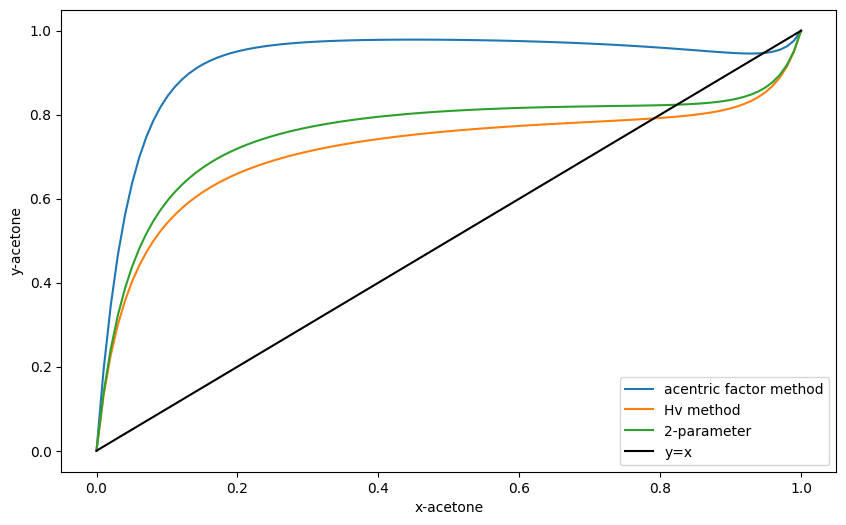

In [10]:
# plot x-y of acetone for all methods in same plot
plt.figure(figsize=(10, 6))
plt.plot(x[:,0], y_ac[:,0], label = 'acentric factor method')
plt.plot(x[:,0], y_hv[:,0], label = 'Hv method')
plt.plot(x[:,0], y_min[:,0], label='2-parameter')
plt.plot(x[:,0],x[:,0], label='y=x', c='k')
plt.xlabel('x-acetone')
plt.ylabel('y-acetone')
plt.legend()
plt.show()
